In [2]:

# STEP 1: IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
# Read the CSV file
ues = pd.read_csv('/kaggle/input/datasets/bellomuhammedmayowa/usedusystem/us_education_system_dataset.csv')

print("Number of rows:", ues.shape[0])
print("Number of columns:", ues.shape[1])

# Display the first five rows
ues.head()


Number of rows: 5000
Number of columns: 35


,institution_id,institution_name,state_code,state_name,county,nces_locale,level,control,title_i_status,total_enrollment,...,math_proficiency_pct,reading_proficiency_pct,graduation_rate_pct,chronic_absenteeism_pct,avg_sat_score,avg_act_score,ap_ib_participation_pct,postsecondary_enrollment_pct,stem_certified_flag,broadband_access_pct
0,US-EDU-10001,Jefferson Elementary School,MA,Massachusetts,Central County,Suburban - Midsize,Elementary School,Public,Title I Schoolwide,447,...,58.3,58.1,80.9,18.0,NaN,NaN,NaN,NaN,No,91.6
1,US-EDU-10002,Lakeshore Middle School,FL,Florida,Miami-Dade County,Suburban - Midsize,Middle School,Private Religious,Not Applicable,293,...,84.8,98.0,93.5,17.8,NaN,NaN,NaN,NaN,No,94.4
2,US-EDU-10003,Meadowbrook Elementary Academy,TX,Texas,Bexar County,City - Large,Elementary School,Private For-Profit,Not Applicable,315,...,54.6,66.2,80.2,19.5,NaN,NaN,NaN,NaN,No,94.0
3,US-EDU-10004,Roosevelt Primary School,FL,Florida,Palm Beach County,Suburban - Large,Elementary School,Public,Not Title I Eligible,389,...,66.1,70.5,82.1,20.5,NaN,NaN,NaN,NaN,No,96.4
4,US-EDU-10005,Highland Park Primary School,MI,Michigan,Macomb County,Suburban - Large,Elementary School,Public,Title I Targeted,397,...,54.6,46.7,90.2,19.9,NaN,NaN,NaN,NaN,No,86.3


In [4]:

# STEP 2: UNDERSTANDING THE DATASET

# Check dataset dimensions
print("Dataset Shape:", ues.shape)

# Check column names
print("\nColumn Names:")
print(ues.columns.tolist())

# Check data types and non-null values
print("\nDataset Information:")
ues.info()

# Statistical summary
print("\nStatistical Summary:")
display(ues.describe())

# Check missing values
print("\nMissing Values:")
missing_values = ues.isnull().sum()
display(missing_values[missing_values > 0].sort_values(ascending=False))

# Check duplicate rows
print("\nDuplicate Rows:", ues.duplicated().sum())


Dataset Shape: (5000, 35)

Column Names:
['institution_id', 'institution_name', 'state_code', 'state_name', 'county', 'nces_locale', 'level', 'control', 'title_i_status', 'total_enrollment', 'number_of_teachers', 'student_teacher_ratio', 'percent_free_reduced_lunch', 'racial_white_pct', 'racial_black_pct', 'racial_hispanic_pct', 'racial_asian_pct', 'racial_native_pct', 'racial_two_or_more_pct', 'special_education_pct', 'english_learner_pct', 'per_pupil_expenditure_usd', 'federal_funding_pct', 'state_funding_pct', 'local_funding_pct', 'math_proficiency_pct', 'reading_proficiency_pct', 'graduation_rate_pct', 'chronic_absenteeism_pct', 'avg_sat_score', 'avg_act_score', 'ap_ib_participation_pct', 'postsecondary_enrollment_pct', 'stem_certified_flag', 'broadband_access_pct']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 35 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                    

,total_enrollment,number_of_teachers,student_teacher_ratio,percent_free_reduced_lunch,racial_white_pct,racial_black_pct,racial_hispanic_pct,racial_asian_pct,racial_native_pct,racial_two_or_more_pct,...,local_funding_pct,math_proficiency_pct,reading_proficiency_pct,graduation_rate_pct,chronic_absenteeism_pct,avg_sat_score,avg_act_score,ap_ib_participation_pct,postsecondary_enrollment_pct,broadband_access_pct
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000.000000,5000.000000,...,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,1625.000000,1625.000000,1421.000000,1421.000000,5000.000000
mean,1375.875400,92.463800,14.928540,41.283700,48.080760,17.4246,21.172960,7.751460,1.438600,4.131620,...,49.091260,60.009120,64.839860,84.926460,19.97656,1232.920000,25.516738,28.423082,66.509571,90.791660
std,3416.620594,225.930376,3.330836,24.092679,19.633591,11.8152,12.408671,6.016449,1.340615,2.110322,...,22.732104,16.545951,16.372625,6.041746,5.91613,91.974662,2.403085,7.745826,8.694913,4.589347
min,80.000000,5.000000,6.000000,0.000000,3.900000,0.8000,1.500000,0.300000,0.100000,0.500000,...,10.300000,12.000000,15.000000,60.000000,4.00000,909.000000,17.100000,2.000000,37.700000,74.500000
25%,438.000000,29.000000,12.600000,21.700000,33.000000,8.4000,11.500000,2.800000,0.200000,2.600000,...,34.900000,48.200000,53.500000,80.800000,16.00000,1169.000000,23.800000,23.100000,60.900000,87.500000
50%,603.000000,42.000000,14.900000,42.400000,48.850000,15.4000,19.900000,6.400000,1.200000,3.900000,...,42.700000,60.100000,64.800000,85.000000,20.00000,1236.000000,25.500000,28.400000,66.600000,90.800000
75%,914.000000,66.000000,17.100000,59.500000,63.900000,24.5000,29.100000,11.600000,2.200000,5.300000,...,52.400000,71.800000,76.400000,89.000000,24.00000,1296.000000,27.300000,33.600000,72.100000,94.200000
max,45252.000000,3279.000000,30.000000,98.000000,92.100000,67.3000,83.200000,36.000000,9.600000,25.400000,...,98.000000,96.000000,98.000000,99.500000,40.20000,1528.000000,33.900000,56.400000,95.000000,99.000000



Missing Values:


postsecondary_enrollment_pct    3579
ap_ib_participation_pct         3579
avg_act_score                   3375
avg_sat_score                   3375
dtype: int64


Duplicate Rows: 0


In [5]:

# STAGE 3: DATA CLEANING

# Create a working copy of the original dataset
ues_clean = ues.copy()

print("Working copy created successfully!")
print("Original dataset shape:", ues.shape)
print("Working dataset shape:", ues_clean.shape)


Working copy created successfully!
Original dataset shape: (5000, 35)
Working dataset shape: (5000, 35)


In [6]:

# CHECK MISSING VALUES

missing = ues_clean.isnull().sum()

missing_summary = pd.DataFrame({
    'Missing Values': missing,
    'Percentage Missing': (missing / len(ues_clean)) * 100
})

missing_summary = missing_summary[
    missing_summary['Missing Values'] > 0
].sort_values(by='Percentage Missing', ascending=False)

display(missing_summary)


,Missing Values,Percentage Missing
postsecondary_enrollment_pct,3579,71.58
ap_ib_participation_pct,3579,71.58
avg_act_score,3375,67.50
avg_sat_score,3375,67.50


In [7]:

# CHECK INVALID PERCENTAGES

percentage_columns = [
    col for col in ues_clean.columns
    if 'pct' in col.lower()
]

for col in percentage_columns:
    invalid = ues_clean[
        (ues_clean[col] < 0) | (ues_clean[col] > 100)
    ]

    print(f"{col}: {len(invalid)} invalid values")


racial_white_pct: 0 invalid values
racial_black_pct: 0 invalid values
racial_hispanic_pct: 0 invalid values
racial_asian_pct: 0 invalid values
racial_native_pct: 0 invalid values
racial_two_or_more_pct: 0 invalid values
special_education_pct: 0 invalid values
english_learner_pct: 0 invalid values
federal_funding_pct: 0 invalid values
state_funding_pct: 0 invalid values
local_funding_pct: 0 invalid values
math_proficiency_pct: 0 invalid values
reading_proficiency_pct: 0 invalid values
graduation_rate_pct: 0 invalid values
chronic_absenteeism_pct: 0 invalid values
ap_ib_participation_pct: 0 invalid values
postsecondary_enrollment_pct: 0 invalid values
broadband_access_pct: 0 invalid values


In [8]:

# INVESTIGATE NUMERICAL OUTLIERS

numerical_columns = ues_clean.select_dtypes(
    include=np.number
).columns

outlier_summary = []

for col in numerical_columns:

    Q1 = ues_clean[col].quantile(0.25)
    Q3 = ues_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = ues_clean[
        (ues_clean[col] < lower_limit) |
        (ues_clean[col] > upper_limit)
    ]

    outlier_summary.append({
        'Variable': col,
        'Outlier Count': len(outliers)
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(
    outlier_summary.sort_values(
        by='Outlier Count',
        ascending=False
    )
)


,Variable,Outlier Count
13,federal_funding_pct,794
15,local_funding_pct,756
14,state_funding_pct,755
1,number_of_teachers,486
0,total_enrollment,480
12,per_pupil_expenditure_usd,152
9,racial_two_or_more_pct,93
5,racial_black_pct,73
8,racial_native_pct,69
7,racial_asian_pct,56


In [9]:

# CHECK CATEGORICAL VARIABLES

categorical_columns = ues_clean.select_dtypes(
    include=['object']
).columns

for col in categorical_columns:
    print(f"\n{col}")
    print(ues_clean[col].value_counts(dropna=False).head(15))



institution_id
institution_id
US-EDU-15000    1
US-EDU-10001    1
US-EDU-10002    1
US-EDU-10003    1
US-EDU-10004    1
US-EDU-10005    1
US-EDU-10006    1
US-EDU-10007    1
US-EDU-14984    1
US-EDU-14983    1
US-EDU-14982    1
US-EDU-14981    1
US-EDU-14980    1
US-EDU-14979    1
US-EDU-14978    1
Name: count, dtype: int64

institution_name
institution_name
Roosevelt Elementary School        32
Centennial Grade School            28
Eisenhower Elementary School       27
Westview Elementary School         26
Willow Creek Elementary Academy    25
Southland Elementary Academy       25
Sunset Grade School                24
Frontier Grade School              24
Marshall Grade School              24
Meadowbrook Grade School           24
Valley View Primary School         24
Westview Elementary Academy        23
Oak Ridge Primary School           23
Hamilton Elementary Academy        23
Horizon Primary School             23
Name: count, dtype: int64

state_code
state_code
CA    531
TX    486

In [10]:
# DESCRIPTIVE STATISTICS FOR NUMERICAL VARIABLES

numerical_summary = ues_clean.describe().T

display(numerical_summary.round(2))

,count,mean,std,min,25%,50%,75%,max
total_enrollment,5000.0,1375.88,3416.62,80.0,438.0,603.00,914.0,45252.0
number_of_teachers,5000.0,92.46,225.93,5.0,29.0,42.00,66.0,3279.0
student_teacher_ratio,5000.0,14.93,3.33,6.0,12.6,14.90,17.1,30.0
percent_free_reduced_lunch,5000.0,41.28,24.09,0.0,21.7,42.40,59.5,98.0
racial_white_pct,5000.0,48.08,19.63,3.9,33.0,48.85,63.9,92.1
racial_black_pct,5000.0,17.42,11.82,0.8,8.4,15.40,24.5,67.3
racial_hispanic_pct,5000.0,21.17,12.41,1.5,11.5,19.90,29.1,83.2
racial_asian_pct,5000.0,7.75,6.02,0.3,2.8,6.40,11.6,36.0
racial_native_pct,5000.0,1.44,1.34,0.1,0.2,1.20,2.2,9.6
racial_two_or_more_pct,5000.0,4.13,2.11,0.5,2.6,3.90,5.3,25.4


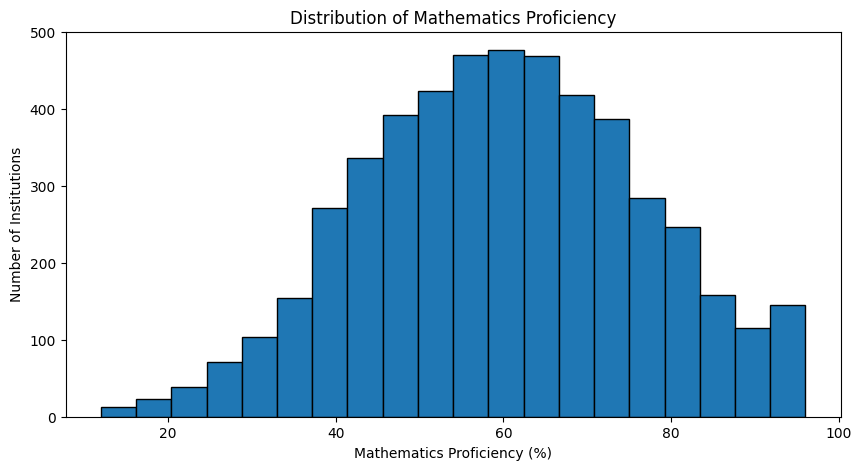

In [11]:
# DISTRIBUTION OF MATHEMATICS PROFICIENCY

plt.figure(figsize=(10, 5))

plt.hist(
    ues_clean['math_proficiency_pct'],
    bins=20,
    edgecolor='black'
)

plt.title('Distribution of Mathematics Proficiency')
plt.xlabel('Mathematics Proficiency (%)')
plt.ylabel('Number of Institutions')

plt.show()

<Figure size 1200x600 with 0 Axes>

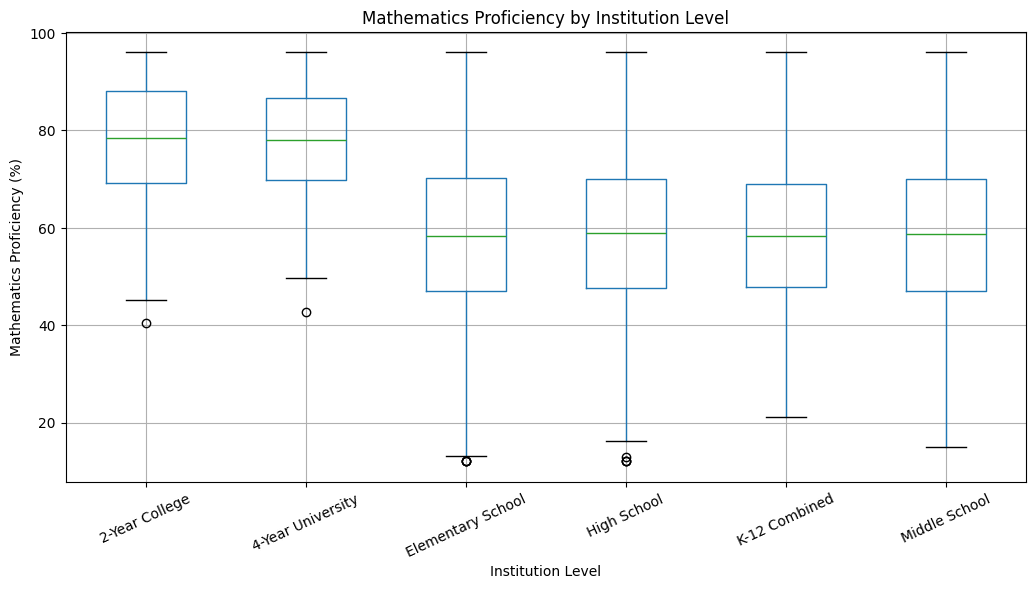

In [12]:
# MATHEMATICS PROFICIENCY BY INSTITUTION LEVEL

plt.figure(figsize=(12, 6))

ues_clean.boxplot(
    column='math_proficiency_pct',
    by='level',
    figsize=(12, 6),
    rot=25
)

plt.suptitle('')
plt.title('Mathematics Proficiency by Institution Level')
plt.xlabel('Institution Level')
plt.ylabel('Mathematics Proficiency (%)')

plt.show()

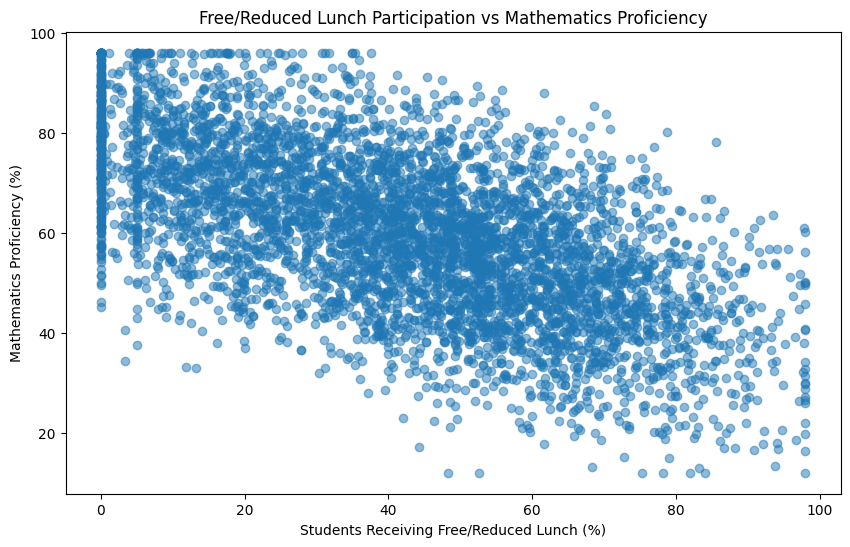

In [13]:
# SOCIOECONOMIC STATUS AND MATHEMATICS PROFICIENCY

plt.figure(figsize=(10, 6))

plt.scatter(
    ues_clean['percent_free_reduced_lunch'],
    ues_clean['math_proficiency_pct'],
    alpha=0.5
)

plt.title('Free/Reduced Lunch Participation vs Mathematics Proficiency')
plt.xlabel('Students Receiving Free/Reduced Lunch (%)')
plt.ylabel('Mathematics Proficiency (%)')

plt.show()

### Socioeconomic Factors and Mathematics Proficiency

A scatterplot was used to investigate the relationship between the percentage of students receiving free or reduced-price lunch and mathematics proficiency.

The visualization reveals a noticeable negative relationship between the two variables. Institutions with higher free or reduced-price lunch participation generally tend to have lower mathematics proficiency.

However, there is considerable variation in proficiency levels across institutions, indicating that socioeconomic status alone may not explain differences in academic performance.

The findings suggest that socioeconomic conditions may be an important factor associated with mathematics proficiency. Further statistical analysis is required to measure the strength of this relationship and investigate other contributing factors.

In [14]:
# CORRELATION BETWEEN SOCIOECONOMIC STATUS AND MATHEMATICS PROFICIENCY

correlation = ues_clean[
    ['percent_free_reduced_lunch', 'math_proficiency_pct']
].corr()

display(correlation.round(3))

,percent_free_reduced_lunch,math_proficiency_pct
percent_free_reduced_lunch,1.000,-0.624
math_proficiency_pct,-0.624,1.000


### Correlation Analysis: Socioeconomic Status and Mathematics Proficiency

Pearson correlation analysis was conducted to measure the relationship between free/reduced lunch participation and mathematics proficiency.

The analysis produced a correlation coefficient of -0.624, indicating a moderately strong negative linear relationship between the two variables.

This suggests that institutions with higher percentages of students receiving free or reduced-price lunch generally tend to have lower mathematics proficiency.

The result supports the pattern observed in the scatterplot and suggests that socioeconomic conditions are an important factor associated with mathematics performance.

However, correlation does not imply causation. Further analysis is necessary to determine how this relationship compares with other institutional factors.

In [15]:
# CORRELATION OF MAJOR FACTORS WITH MATHEMATICS PROFICIENCY

selected_columns = [
    'per_pupil_expenditure_usd',
    'broadband_access_pct',
    'student_teacher_ratio',
    'reading_proficiency_pct',
    'chronic_absenteeism_pct',
    'percent_free_reduced_lunch',
    'federal_funding_pct',
    'state_funding_pct',
    'local_funding_pct',
    'math_proficiency_pct'
]

correlation_matrix = ues_clean[selected_columns].corr()

math_correlations = correlation_matrix[
    'math_proficiency_pct'
].sort_values(ascending=False)

display(math_correlations.round(3))

math_proficiency_pct          1.000
reading_proficiency_pct       0.770
broadband_access_pct          0.487
local_funding_pct             0.338
per_pupil_expenditure_usd     0.337
student_teacher_ratio        -0.059
state_funding_pct            -0.302
federal_funding_pct          -0.372
chronic_absenteeism_pct      -0.448
percent_free_reduced_lunch   -0.624
Name: math_proficiency_pct, dtype: float64

### Correlation Analysis of Institutional Factors and Mathematics Proficiency

Correlation analysis was conducted to examine the relationships between selected institutional characteristics and mathematics proficiency.

Reading proficiency showed the strongest positive correlation with mathematics proficiency (r = 0.770), followed by broadband access (r = 0.487), local funding (r = 0.338), and per-pupil expenditure (r = 0.337).

On the negative side, free/reduced lunch participation had the strongest negative correlation (r = -0.624), followed by chronic absenteeism (r = -0.448), federal funding (r = -0.372), and state funding (r = -0.302).

Student-teacher ratio had a very weak negative correlation (r = -0.059).

These findings suggest that academic performance, socioeconomic conditions, broadband access, and institutional funding patterns are associated with mathematics proficiency. However, correlation does not establish causation, and further analysis is required to examine the combined influence of these factors.

In [16]:
# PREPARE DATA FOR MACHINE LEARNING

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Select input variables
features = [
    'reading_proficiency_pct',
    'percent_free_reduced_lunch',
    'broadband_access_pct',
    'per_pupil_expenditure_usd',
    'student_teacher_ratio',
    'chronic_absenteeism_pct',
    'state_funding_pct',
    'local_funding_pct',
    'level',
    'control',
    'title_i_status',
    'stem_certified_flag'
]

# Define inputs and target
X = ues_clean[features]
y = ues_clean['math_proficiency_pct']

# Identify numerical and categorical variables
numerical_features = [
    'reading_proficiency_pct',
    'percent_free_reduced_lunch',
    'broadband_access_pct',
    'per_pupil_expenditure_usd',
    'student_teacher_ratio',
    'chronic_absenteeism_pct',
    'state_funding_pct',
    'local_funding_pct'
]

categorical_features = [
    'level',
    'control',
    'title_i_status',
    'stem_certified_flag'
]

# Convert categorical variables into numerical format
preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough'
)

# Create the regression pipeline
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 4000
Testing records: 1000


In [17]:
# TRAIN THE MULTIPLE LINEAR REGRESSION MODEL

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [18]:
# MAKE PREDICTIONS

y_pred = model.predict(X_test)

# EVALUATE MODEL PERFORMANCE

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MODEL PERFORMANCE")
print("-------------------------")
print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R-squared Score:", round(r2, 3))

MODEL PERFORMANCE
-------------------------
Mean Absolute Error: 8.11
Mean Squared Error: 100.43
Root Mean Squared Error: 10.02
R-squared Score: 0.627


### Multiple Linear Regression Model Evaluation

A Multiple Linear Regression model was developed to predict mathematics proficiency using selected institutional, socioeconomic, academic, and technological characteristics.

The dataset was divided into 80% training data (4,000 records) and 20% testing data (1,000 records).

The model was evaluated using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and the R-squared score.

The model achieved the following results:

- Mean Absolute Error: 8.11
- Mean Squared Error: 100.43
- Root Mean Squared Error: 10.02
- R-squared Score: 0.627

The R-squared score indicates that the model explains approximately 62.7% of the variation in mathematics proficiency in the test dataset. The MAE indicates an average prediction error of approximately 8.11 percentage points.

Overall, the model demonstrates a useful ability to predict mathematics proficiency based on the selected institutional characteristics. However, its predictions are not exact, and other factors may account for some of the unexplained variation.

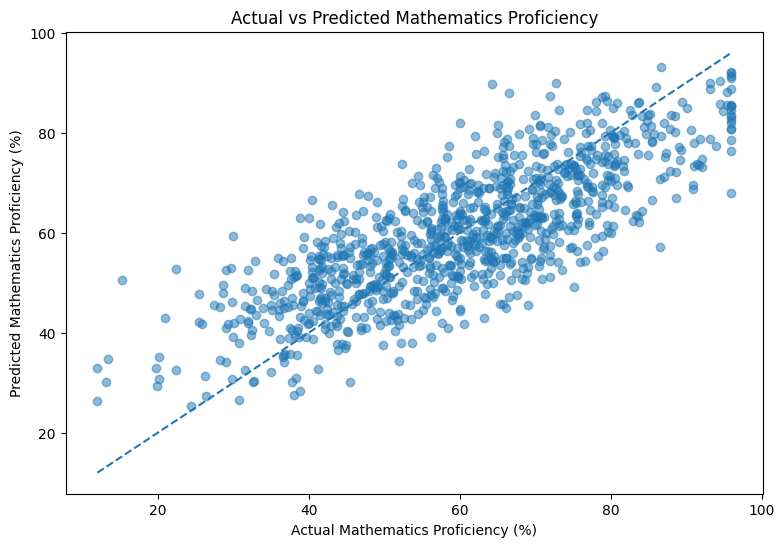

In [19]:
# ACTUAL VS PREDICTED MATHEMATICS PROFICIENCY

plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.title('Actual vs Predicted Mathematics Proficiency')
plt.xlabel('Actual Mathematics Proficiency (%)')
plt.ylabel('Predicted Mathematics Proficiency (%)')

plt.show()

### Actual vs Predicted Mathematics Proficiency

A scatterplot was created to compare the actual mathematics proficiency scores with the values predicted by the Multiple Linear Regression model.

The visualization shows a clear positive relationship between actual and predicted values. Many observations are reasonably close to the diagonal reference line, which represents perfect predictions.

However, some observations are further away from the reference line, indicating prediction errors. The model also appears to overestimate some lower proficiency scores and underestimate some higher proficiency scores.

Overall, the visualization supports the model evaluation results, suggesting that the regression model captures important patterns in mathematics proficiency, although prediction errors remain.

In [20]:
# IDENTIFY THE MOST IMPORTANT PREDICTIVE FEATURES

from sklearn.inspection import permutation_importance

importance_results = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='r2'
)

importance_summary = pd.DataFrame({
    'Feature': features,
    'Importance': importance_results.importances_mean,
    'Standard Deviation': importance_results.importances_std
})

importance_summary = importance_summary.sort_values(
    by='Importance',
    ascending=False
)

display(importance_summary.round(4))

,Feature,Importance,Standard Deviation
0,reading_proficiency_pct,0.6505,0.0278
1,percent_free_reduced_lunch,0.0612,0.0069
5,chronic_absenteeism_pct,0.0208,0.0035
10,title_i_status,0.0069,0.0025
3,per_pupil_expenditure_usd,0.0061,0.0032
9,control,0.0022,0.0013
8,level,0.0018,0.0007
4,student_teacher_ratio,0.0008,0.0008
11,stem_certified_flag,0.0004,0.0003
7,local_funding_pct,0.0002,0.0004


In [21]:
# IDENTIFY THE MOST IMPORTANT PREDICTIVE FEATURES

from sklearn.inspection import permutation_importance

importance_results = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='r2'
)

importance_summary = pd.DataFrame({
    'Feature': features,
    'Importance': importance_results.importances_mean,
    'Standard Deviation': importance_results.importances_std
})

importance_summary = importance_summary.sort_values(
    by='Importance',
    ascending=False
)

display(importance_summary.round(4))

,Feature,Importance,Standard Deviation
0,reading_proficiency_pct,0.6505,0.0278
1,percent_free_reduced_lunch,0.0612,0.0069
5,chronic_absenteeism_pct,0.0208,0.0035
10,title_i_status,0.0069,0.0025
3,per_pupil_expenditure_usd,0.0061,0.0032
9,control,0.0022,0.0013
8,level,0.0018,0.0007
4,student_teacher_ratio,0.0008,0.0008
11,stem_certified_flag,0.0004,0.0003
7,local_funding_pct,0.0002,0.0004


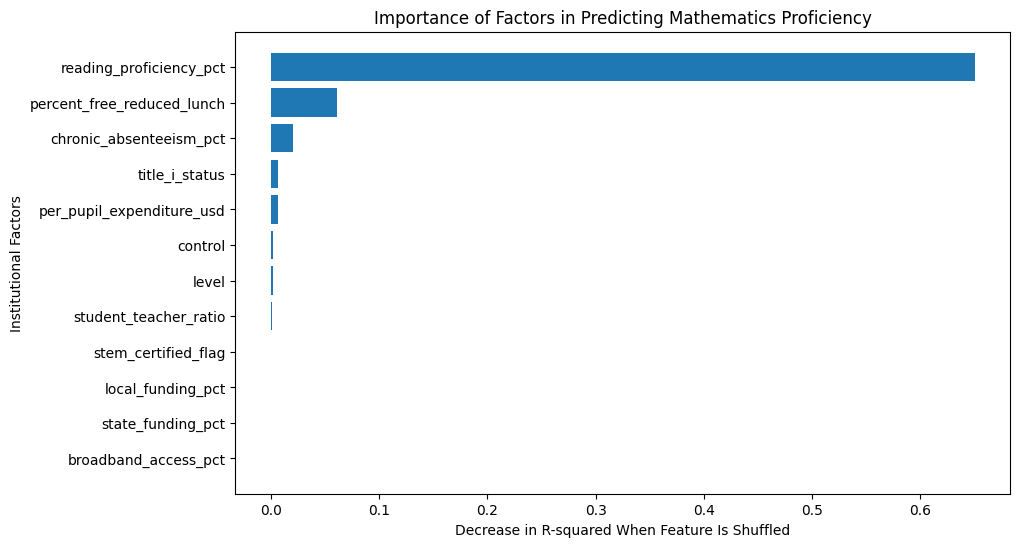

In [22]:
# VISUALIZE FEATURE IMPORTANCE

plt.figure(figsize=(10, 6))

plt.barh(
    importance_summary['Feature'],
    importance_summary['Importance']
)

plt.gca().invert_yaxis()

plt.title('Importance of Factors in Predicting Mathematics Proficiency')
plt.xlabel('Decrease in R-squared When Feature Is Shuffled')
plt.ylabel('Institutional Factors')

plt.show()

### Feature Importance Analysis

Permutation importance was used to identify the institutional characteristics that contribute most to the predictive performance of the Multiple Linear Regression model.

The results show that reading proficiency is the most influential predictive feature by a considerable margin. Free/reduced lunch participation is the second most important feature, followed by chronic absenteeism.

Per-pupil expenditure and Title I status make smaller contributions, while several other institutional characteristics have relatively low individual importance scores.

These findings suggest that academic performance, socioeconomic conditions, and student attendance contain useful information for predicting mathematics proficiency.

However, feature importance measures predictive contribution rather than causal influence. The results should therefore be interpreted as associations within the fitted model.

In [23]:
# DISPLAY EXACT FEATURE IMPORTANCE VALUES

display(importance_summary.round(4))

,Feature,Importance,Standard Deviation
0,reading_proficiency_pct,0.6505,0.0278
1,percent_free_reduced_lunch,0.0612,0.0069
5,chronic_absenteeism_pct,0.0208,0.0035
10,title_i_status,0.0069,0.0025
3,per_pupil_expenditure_usd,0.0061,0.0032
9,control,0.0022,0.0013
8,level,0.0018,0.0007
4,student_teacher_ratio,0.0008,0.0008
11,stem_certified_flag,0.0004,0.0003
7,local_funding_pct,0.0002,0.0004


### Detailed Feature Importance Analysis

Permutation importance was used to evaluate the contribution of each selected feature to the predictive performance of the Multiple Linear Regression model.

Reading proficiency emerged as the most influential predictor, with an importance score of 0.6505. Free/reduced lunch participation ranked second with 0.0612, followed by chronic absenteeism with 0.0208.

Title I status and per-pupil expenditure had relatively small importance scores of 0.0069 and 0.0061, respectively. The remaining features contributed very little individually to the model's predictive performance.

Broadband access recorded a slightly negative importance score of -0.0003, suggesting that it provided no meaningful additional predictive contribution in this model.

Overall, reading proficiency, socioeconomic conditions, and chronic absenteeism were the most useful predictors among the selected variables. These results describe predictive importance and should not be interpreted as evidence of causation.

In [24]:
# SECOND MODEL: EXCLUDING READING PROFICIENCY

features_without_reading = [
    'percent_free_reduced_lunch',
    'broadband_access_pct',
    'per_pupil_expenditure_usd',
    'student_teacher_ratio',
    'chronic_absenteeism_pct',
    'state_funding_pct',
    'local_funding_pct',
    'level',
    'control',
    'title_i_status',
    'stem_certified_flag'
]

X_second = ues_clean[features_without_reading]
y_second = ues_clean['math_proficiency_pct']

numerical_features_second = [
    'percent_free_reduced_lunch',
    'broadband_access_pct',
    'per_pupil_expenditure_usd',
    'student_teacher_ratio',
    'chronic_absenteeism_pct',
    'state_funding_pct',
    'local_funding_pct'
]

categorical_features_second = [
    'level',
    'control',
    'title_i_status',
    'stem_certified_flag'
]

preprocessor_second = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'),
         categorical_features_second)
    ],
    remainder='passthrough'
)

model_second = Pipeline(steps=[
    ('preprocessor', preprocessor_second),
    ('regressor', LinearRegression())
])

X_train_second, X_test_second, y_train_second, y_test_second = train_test_split(
    X_second,
    y_second,
    test_size=0.2,
    random_state=42
)

model_second.fit(X_train_second, y_train_second)

y_pred_second = model_second.predict(X_test_second)

mae_second = mean_absolute_error(y_test_second, y_pred_second)
rmse_second = np.sqrt(mean_squared_error(y_test_second, y_pred_second))
r2_second = r2_score(y_test_second, y_pred_second)

print("SECOND MODEL PERFORMANCE")
print("-------------------------")
print("Mean Absolute Error:", round(mae_second, 2))
print("Root Mean Squared Error:", round(rmse_second, 2))
print("R-squared Score:", round(r2_second, 3))

SECOND MODEL PERFORMANCE
-------------------------
Mean Absolute Error: 10.04
Root Mean Squared Error: 12.5
R-squared Score: 0.42


### Comparison of Regression Models

Two Multiple Linear Regression models were developed to predict mathematics proficiency.

The first model included reading proficiency alongside institutional, socioeconomic, academic, and technological characteristics. It achieved an R-squared score of 0.627, a Mean Absolute Error of 8.11, and a Root Mean Squared Error of 10.02.

The second model excluded reading proficiency and relied on institutional and socioeconomic characteristics. It achieved an R-squared score of 0.420, a Mean Absolute Error of 10.04, and a Root Mean Squared Error of 12.50.

The comparison shows that excluding reading proficiency reduced the model's explanatory power by 20.7 percentage points.

This suggests that reading proficiency contains substantial predictive information about mathematics proficiency. Nevertheless, the second model demonstrates that institutional and socioeconomic characteristics also provide meaningful predictive information.

Both models provide useful insights into the factors associated with mathematics proficiency.

In [25]:
# FEATURE IMPORTANCE FOR THE SECOND MODEL

importance_second = permutation_importance(
    model_second,
    X_test_second,
    y_test_second,
    n_repeats=10,
    random_state=42,
    scoring='r2'
)

importance_summary_second = pd.DataFrame({
    'Feature': features_without_reading,
    'Importance': importance_second.importances_mean,
    'Standard Deviation': importance_second.importances_std
})

importance_summary_second = importance_summary_second.sort_values(
    by='Importance',
    ascending=False
)

display(importance_summary_second.round(4))

,Feature,Importance,Standard Deviation
0,percent_free_reduced_lunch,0.4209,0.0164
4,chronic_absenteeism_pct,0.1160,0.0095
2,per_pupil_expenditure_usd,0.0260,0.0109
6,local_funding_pct,0.0084,0.0038
8,control,0.0077,0.0028
5,state_funding_pct,0.0048,0.0029
9,title_i_status,0.0043,0.0026
7,level,0.0015,0.0007
10,stem_certified_flag,0.0009,0.0005
3,student_teacher_ratio,0.0004,0.0003


### Feature Importance Analysis Without Reading Proficiency

Permutation importance was conducted on the second regression model to identify the most influential institutional and socioeconomic predictors of mathematics proficiency without including reading proficiency.

Free/reduced lunch participation emerged as the most influential feature, with an importance score of 0.4209. Chronic absenteeism ranked second with 0.1160, while per-pupil expenditure ranked third with 0.0260.

Local funding, institution control, state funding, and Title I status made smaller contributions to predictive performance. Institution level, STEM certification, and student-teacher ratio had very low importance scores.

Broadband access recorded a slightly negative importance score of -0.0009, indicating that it did not provide meaningful additional predictive information in this model.

Overall, the analysis suggests that socioeconomic conditions and student attendance are particularly important predictors of mathematics proficiency among the institutional characteristics examined.

# Conclusion

This study investigated the institutional, socioeconomic, staffing, funding, and technological characteristics associated with mathematics proficiency across 5,000 educational institutions in the United States.

The exploratory data analysis revealed considerable variation in mathematics proficiency across institutions. The average mathematics proficiency was 60.01%, while reading proficiency averaged 64.84%.

The correlation analysis identified several important relationships. Reading proficiency had the strongest positive correlation with mathematics proficiency (r = 0.770), while free/reduced lunch participation had a moderately strong negative correlation (r = -0.624). Chronic absenteeism also showed a negative relationship with mathematics proficiency (r = -0.448), while broadband access had a positive relationship (r = 0.487).

Two Multiple Linear Regression models were developed. The first model, which included reading proficiency, achieved an R-squared score of 0.627. The second model, which excluded reading proficiency, achieved an R-squared score of 0.420.

The feature importance analysis of the second model identified free/reduced lunch participation as the strongest predictor, followed by chronic absenteeism and per-pupil expenditure.

These findings suggest that socioeconomic conditions and student attendance are important factors associated with mathematics proficiency. Reading proficiency also provides substantial predictive information about mathematics performance.

Overall, the study demonstrates that mathematics proficiency is associated with multiple institutional and socioeconomic characteristics. The findings can help inform discussions about educational inequality, student support, and institutional improvement.

However, the analysis identifies associations and predictive patterns rather than causal relationships.

# Recommendations

Based on the findings of this study, the following recommendations are proposed:

1. **Strengthen support for economically disadvantaged students:** Institutions serving higher proportions of students receiving free or reduced-price lunch may benefit from targeted academic support, learning resources, and additional student assistance.

2. **Improve student attendance:** Educational institutions should strengthen attendance monitoring, identify barriers to regular attendance, and provide appropriate interventions for students experiencing chronic absenteeism.

3. **Support literacy and mathematics together:** The strong positive relationship between reading and mathematics proficiency suggests that strengthening reading comprehension may also support mathematics learning.

4. **Review educational resource allocation:** Institutions and policymakers should examine how per-pupil expenditure and funding arrangements relate to educational outcomes and whether resources are reaching institutions with greater needs.

5. **Improve access to educational technology:** Although broadband access had limited additional predictive importance in the regression model, institutions should continue addressing digital access gaps to support equitable learning opportunities.

6. **Use institutional data for targeted interventions:** Education stakeholders can use institutional performance and socioeconomic indicators to identify areas requiring additional support and monitor educational outcomes over time.

# Limitations of the Study

1. **Observational data:** The analysis identifies associations between institutional characteristics and mathematics proficiency but cannot establish causal relationships.

2. **Missing values:** SAT scores, ACT scores, AP/IB participation, and postsecondary enrollment contain substantial missing data, limiting their inclusion in the main regression models.

3. **Model limitations:** Multiple Linear Regression assumes a linear relationship between predictors and the target. More complex relationships may not be fully captured.

4. **Predictive limitations:** The second regression model achieved an R-squared score of 0.420, indicating that 58% of the variation in mathematics proficiency remains unexplained.

5. **Correlated predictors:** Some institutional characteristics may be related to one another, which can affect the interpretation of feature importance.

6. **Generalizability:** The findings reflect the institutions represented in the dataset and should not automatically be generalized to every educational institution in the United States.